<a href="https://colab.research.google.com/github/WaqasNoor08/Brand-Sentiment-Analysis-/blob/main/Brand_Sentiment_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Brand Sentiment Analysis (YouTube Comments)

## Cell 1: Libraries install

In [ ]:
!pip install -q google-api-python-client vaderSentiment wordcloud

## Cell 2: Settings (yahan brand aur API key daalo)

In [ ]:

from getpass import getpass

BRAND = "Khaadi"            # <- apne brand ka naam
TARGET_COMMENTS = 2200
COMMENTS_PER_VIDEO = 300    # har video se max comments
MODEL = "vader"             # "vader" ya "xlmr"

API_KEY = getpass("YouTube API key paste karo: ")

YouTube API key paste karo: ··········


## Cell 3: Comments scrape karo

In [ ]:

import time
import pandas as pd
from googleapiclient.discovery import build
from googleapiclient.errors import HttpError

yt = build("youtube", "v3", developerKey=API_KEY)

def search_videos(query, max_pages=3):
    token, found = None, []
    for _ in range(max_pages):
        res = yt.search().list(q=query, part="id,snippet", type="video",
                               maxResults=50, pageToken=token,
                               order="relevance").execute()
        found += [(i["id"]["videoId"], i["snippet"]["title"]) for i in res["items"]]
        token = res.get("nextPageToken")
        if not token:
            break
    return found

def get_comments(video_id, title, max_comments):
    rows, token = [], None
    while len(rows) < max_comments:
        try:
            res = yt.commentThreads().list(part="snippet", videoId=video_id,
                                           maxResults=100, pageToken=token,
                                           textFormat="plainText",
                                           order="relevance").execute()
        except HttpError:
            break  # is video ke comments band hain
        for it in res["items"]:
            s = it["snippet"]["topLevelComment"]["snippet"]
            rows.append({"video_title": title, "comment": s["textDisplay"],
                         "likes": s["likeCount"], "published_at": s["publishedAt"]})
        token = res.get("nextPageToken")
        if not token:
            break
        time.sleep(0.2)
    return rows[:max_comments]

queries = [f"{BRAND} review", f"{BRAND} collection", f"{BRAND} unboxing",
           f"{BRAND} haul", f"{BRAND} sale"]

rows, seen_videos, seen_comments = [], set(), set()

for q in queries:
    if len(seen_comments) >= TARGET_COMMENTS:
        break
    print(f"\n--- Search: {q} ---")
    for vid, title in search_videos(q):
        if vid in seen_videos:
            continue
        seen_videos.add(vid)
        for r in get_comments(vid, title, COMMENTS_PER_VIDEO):
            if r["comment"] not in seen_comments:
                seen_comments.add(r["comment"])
                rows.append(r)
        print(f"{len(seen_comments)} comments | {title[:50]}")
        if len(seen_comments) >= TARGET_COMMENTS:
            break

df = pd.DataFrame(rows[:TARGET_COMMENTS]).reset_index(drop=True)
print("\nTotal comments:", len(df), "| Videos used:", len(seen_videos))
df.head()


--- Search: Khaadi review ---
2 comments | How Khaadi kurta looks on model Vs Me | Online vs 
2 comments | Khaadi Perfume &amp; Body Mist Collection Review 💕
6 comments | Khaadi Winter Collection 2026 ✨️ | Prices &amp; Fl
17 comments | Unboxing of khaadi || honest review
17 comments | Khaadi Clothing Review 🇵🇰 | Is Khaadi Really Worth
146 comments | the real-est try-on haul *unfiltered* ft. Khaadi
151 comments | Khaadi Shalwar Review: Is It Worth the Hype? #fash
162 comments | khaadi SUPER FLAT 70%OFF GRAND SALE 😱🔥😍 khaadi sal
165 comments | Khaadi New Winter Collection 2026😍Khaadi Winter Ca
165 comments | Khaadi  || Khaadi Sale Flat 40 % OFF Unstitched &a
168 comments | Khaadi Sale Today 2025 #khaadi #sale #summercollec
170 comments | Khaadi To List On PSX | Nukta Business
172 comments | Review #shorts #Khaadi #branding
177 comments | Is Khaadi Perfume Overrated?| My Honest Review!🚨
178 comments | Khaadi Sale Today Flat 50% Off|| Khaadi Sale
179 comments | khaadi New Signature Pret 2

638 comments | Khadi herbal mehndi full review 👍 #haircolor #natu
638 comments | Best Indian Cloth is Khadi...#shorts #viral #freef
659 comments | Stronger roots, shiny hair! 🌿 Khadi Amla &amp; Bhr
699 comments | Khaadi Perfume Review from new range - Oh So Exoti
715 comments | Khaadi Beautiful New Eid Collection 2026❣️Khaadi N
725 comments | Khadi natural 🌱 shampoo and conditioner review #kh
744 comments | Review of Khadi Natural Shampoo and Conditioner af
751 comments | KHAADI SUPER SALE 2026 🔥📣 Huge Restock 😱 Khaadi sa
754 comments | Khadi Natural Facewash| #aloevera #scrub #facewash
793 comments | Khadi Shikakai Shampoo Review | apke Reviews
806 comments | KHADI NATURAL ROSE WATER SOAP in Dmart #khadi #nat
830 comments | Khaadi summer #khaadi #youtubeshorts #shorts #vira
830 comments | khadi natural Alovera gel review #shorts #viralvid
862 comments | Khaadi 70% OFF SALE - My Online Shopping Review
869 comments | KHAADI SUPER SALE 2026 🔥📣 Huge Restock 😱 Khaadi sa
869 comments | khaa

,video_title,comment,likes,published_at
0,How Khaadi kurta looks on model Vs Me | Online...,It's interesting how different it looks. Those...,1,2023-09-14T00:30:37Z
1,How Khaadi kurta looks on model Vs Me | Online...,What size r wearing? In khaadi?,0,2026-04-20T04:44:44Z
2,Khaadi Winter Collection 2026 ✨️ | Prices &amp...,Walaikum assalam,0,2026-10-29T09:53:57Z
3,Khaadi Winter Collection 2026 ✨️ | Prices &amp...,"Khadi has real variety, but it gettin expansiv...",1,2026-10-30T01:24:32Z
4,Khaadi Winter Collection 2026 ✨️ | Prices &amp...,Khaadi is too pricy compared to other brands w...,1,2026-10-29T18:38:18Z


## Cell 4: Sentiment analysis

In [12]:
import re

def clean(t):
    t = re.sub(r"http\S+|www\.\S+", " ", str(t))
    t = re.sub(r"@\w+", " ", t)
    return re.sub(r"\s+", " ", t).strip()

df["clean"] = df["comment"].map(clean)
df = df[df["clean"].str.len() > 2].reset_index(drop=True)

if MODEL == "vader":
    from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
    sia = SentimentIntensityAnalyzer()
    scores = [sia.polarity_scores(t)["compound"] for t in df["clean"]]
    df["score"] = scores
    df["sentiment"] = ["Positive" if s >= 0.05 else "Negative" if s <= -0.05 else "Neutral"
                       for s in scores]
else:
    !pip install -q transformers torch
    from transformers import pipeline
    clf = pipeline("sentiment-analysis",
                   model="cardiffnlp/twitter-xlm-roberta-base-sentiment",
                   truncation=True, max_length=128)
    res = clf(df["clean"].tolist(), batch_size=32)
    df["sentiment"] = [r["label"].capitalize() for r in res]
    df["score"] = [r["score"] for r in res]

counts = df["sentiment"].value_counts()
print(counts)
print((counts / len(df) * 100).round(1).astype(str) + " %")

sentiment
Positive    1050
Neutral      926
Negative     199
Name: count, dtype: int64
sentiment
Positive    48.3 %
Neutral     42.6 %
Negative     9.1 %
Name: count, dtype: object


## Cell 5: Charts

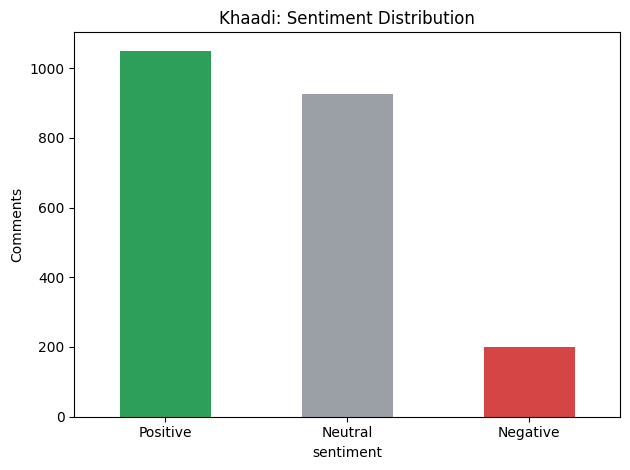

/tmp/ipykernel_3027/723089202.py:20: UserWarning: Glyph 127800 (\N{CHERRY BLOSSOM}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.savefig("per_video.png", dpi=150); plt.show()
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 127800 (\N{CHERRY BLOSSOM}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


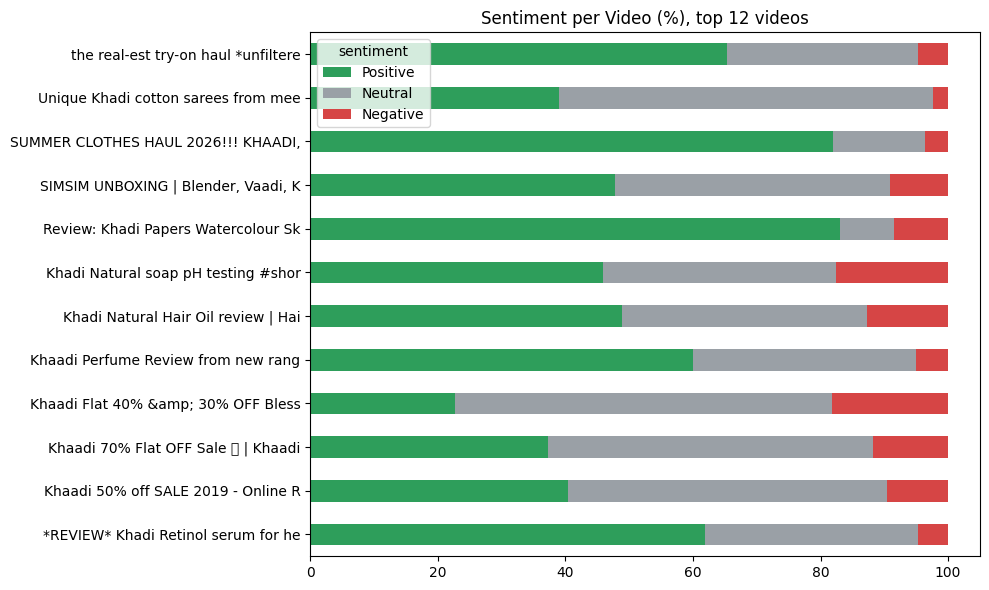

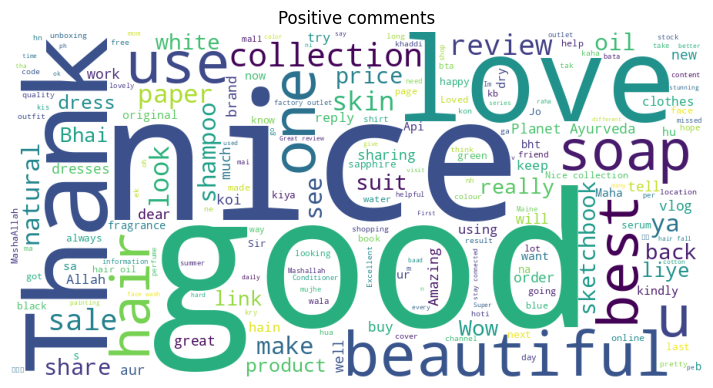

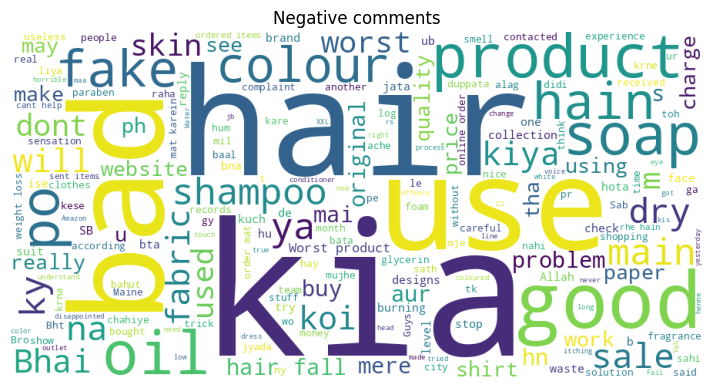

In [13]:

import matplotlib.pyplot as plt
from wordcloud import WordCloud, STOPWORDS

colors = {"Positive": "#2e9e5b", "Neutral": "#9aa0a6", "Negative": "#d64545"}

# 1) Overall distribution
counts.plot(kind="bar", color=[colors.get(k, "#555") for k in counts.index])
plt.title(f"{BRAND}: Sentiment Distribution"); plt.ylabel("Comments")
plt.xticks(rotation=0); plt.tight_layout()
plt.savefig("distribution.png", dpi=150); plt.show()

# 2) Per video: sirf top 12 videos (zyada comments wali)
top = df["video_title"].value_counts().head(12).index
sub = df[df["video_title"].isin(top)]
pv = pd.crosstab(sub["video_title"].str[:35], sub["sentiment"], normalize="index") * 100
pv = pv[[c for c in ["Positive", "Neutral", "Negative"] if c in pv.columns]]
fig, ax = plt.subplots(figsize=(10, 6))
pv.plot(kind="barh", stacked=True, ax=ax, color=[colors[c] for c in pv.columns])
ax.set_title("Sentiment per Video (%), top 12 videos"); ax.set_ylabel("")
plt.tight_layout(); plt.savefig("per_video.png", dpi=150); plt.show()

# 3) Word clouds (faltu words hata kar)
extra = {"video", "videos", "please", "plz", "pls", "khadi", BRAND.lower(),
         "ka", "ki", "ke", "ko", "hai", "hy", "ho", "h", "ha", "ye", "yeh",
         "bhi", "hi", "se", "me", "mein", "kya", "ap", "aap", "kr", "kar",
         "karo", "nhi", "ji", "sis", "sister", "mam", "madam", "apa"}
stop = STOPWORDS | extra
for label in ["Positive", "Negative"]:
    text = " ".join(df.loc[df["sentiment"] == label, "clean"])
    if len(text) > 20:
        wc = WordCloud(width=900, height=450, background_color="white",
                       stopwords=stop).generate(text)
        plt.figure(figsize=(9, 4.5)); plt.imshow(wc); plt.axis("off")
        plt.title(f"{label} comments"); plt.savefig(f"wordcloud_{label.lower()}.png", dpi=150)
        plt.show()

## Cell 6: Sample comments dekho (accuracy check)

In [ ]:
for label in ["Positive", "Negative", "Neutral"]:
    print(f"\n=== {label} ===")
    for t in df[df["sentiment"] == label]["clean"].head(5):
        print("-", t[:150])


=== Positive ===
- It's interesting how different it looks. Those colors really match you!
- Khaadi is too pricy compared to other brands with similar stuff and on top you gotta purchase everything separately
- Good one 😮
- ❤❤❤❤❤
- good job, 👍

=== Negative ===
- Yah outlet kaha p h Pakistan m h kia kis city se
- Yes quality of khaadi getting low 😢
- So true... Khaadi really disappointed me with their designs for the prices .. last 2 /3 years they are just filling racks with whatever.. also unstich
- The struggle for XL / XXL is real Do make more of these vlogs. Hate the Taylors torture but no options available in ready made
- Khaadi has pretty clothes but they dont fit me and its depressing 😢😢😢

=== Neutral ===
- What size r wearing? In khaadi?
- Walaikum assalam
- Khadi has real variety, but it gettin expansive. It’s almost double prices since last year.
- Ma'am online order kren to Khaadi ka handbag wala envelope ata hai? Ya sirf lamination packing ati hai?
- Sorry but I think it's

## Cell 7: Results download karo

In [14]:
import glob, zipfile
from google.colab import files

df.to_csv("results.csv", index=False, encoding="utf-8-sig")
with zipfile.ZipFile("results.zip", "w") as z:
    for f in ["results.csv"] + glob.glob("*.png"):
        z.write(f)
files.download("results.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>